# Làm sạch và Chuẩn bị dữ liệu – Dự đoán phí vận chuyển Olist

Nhóm 8, lớp AI2107, môn ADY201M, FALL26

---

## 1.1. Bối cảnh và lý do chọn đề tài

Thương mại điện tử đang phát triển mạnh mẽ, kéo theo vai trò ngày càng quan trọng của chi phí vận chuyển trong quyết định mua sắm trực tuyến. Theo VECOM (2025), thị trường bán lẻ trực tuyến Việt Nam đạt khoảng **32 tỷ USD năm 2024**, tăng 27% so với năm trước. Tuy nhiên, chi phí logistics vẫn ở mức cao, chiếm khoảng **20,9% GDP**, trong đó vận tải chiếm 59% tổng chi phí logistics.

Theo Baymard Institute, **48% người mua sắm trực tuyến từ bỏ giỏ hàng** do các chi phí phát sinh như phí vận chuyển, thuế và phụ phí quá cao. Tại Brazil, nghiên cứu của ABComm cũng ghi nhận vận chuyển chiếm **65,9% chi phí logistics thương mại điện tử**, cho thấy tầm quan trọng của việc kiểm soát và dự báo chi phí này.

Từ thực tế đó, nhóm lựa chọn đề tài **“Ứng dụng Phân tích Dữ liệu trong Dự đoán Phí Vận chuyển Đơn hàng Thương mại điện tử”** nhằm xây dựng mô hình dự đoán phí vận chuyển dựa trên các yếu tố như cân nặng, thể tích sản phẩm, khoảng cách địa lý và số lượng hàng hóa. Kết quả kỳ vọng giúp người bán ước tính chi phí minh bạch hơn, hỗ trợ quyết định kinh doanh và tối ưu hoạt động logistics. Đồng thời, dự án tạo cơ hội vận dụng kiến thức về xử lý dữ liệu, xây dựng đặc trưng và mô hình hồi quy vào thực tiễn.

## Nguồn tham khảo

- VECOM (2025): https://vecom.vn/bao-cao-chi-so-thuong-mai-dien-tu-viet-nam-2025
- VCCI / thông tin về chi phí logistics: https://vnbusiness.vn/chi-phi-logistics-qua-cao.html
- Baymard Institute (dẫn lại): https://hostadvice.com/blog/monetization/ecommerce/abandoned-cart-statistics/
- ABComm: https://abiacom.org/noticias/pesquisa-logistica-no-e-commerce-brasileiro-2019/

Nạp thư viện và đặt tùy chọn hiển thị.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 100

Khai báo hàm step(), ghi_thay_doi() và haversine_km().

In [2]:
audit_rows = []
change_rows = []

def step(frame, keep, section, rule, loai, co_xem_freight):
    truoc = len(frame)
    out = frame[keep].copy()
    audit_rows.append({
        'muc': section, 'quy_tac': rule, 'loai_quy_tac': loai, 'co_xem_freight': co_xem_freight,
        'truoc': truoc, 'sau': len(out), 'so_dong_loai': truoc - len(out),
    })
    print(f'{section:<8} {rule:<42} {truoc:>7} -> {len(out):>7} (loai {truoc - len(out)})')
    return out

def ghi_thay_doi(section, rule, so_dong, loai, co_xem_freight):
    change_rows.append({
        'muc': section, 'quy_tac': rule, 'loai_quy_tac': loai,
        'co_xem_freight': co_xem_freight, 'so_dong_anh_huong': so_dong,
    })
    print(f'{section:<8} {rule:<42} anh huong {so_dong} dong')

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

---

## 1. Bối cảnh và mục tiêu bài toán

### 1.2 Phát biểu bài toán

- Loại bài toán: hồi quy.
- Đơn vị quan sát: một sản phẩm trong một đơn, xác định bởi cặp (order_id, order_item_id).
- Biến mục tiêu: freight_value, đơn vị real Brazil (BRL).
- Đầu vào: cân nặng, kích thước, thể tích, danh mục và giá của sản phẩm; bang, tọa độ và khoảng cách giữa người bán và khách; thời điểm mua; số sản phẩm trong đơn.
- Đầu ra: phí vận chuyển dự đoán cho từng sản phẩm.

### 1.3 Thông tin được phép dùng làm đầu vào

Mô hình chỉ được dùng thông tin đã có tại thời điểm đặt hàng, để tránh rò rỉ dữ liệu (đưa vào mô hình thông tin chưa tồn tại khi cần dự đoán).

| Nhóm thông tin | Có tại thời điểm đặt hàng | Dùng làm đầu vào |
|---|---|---|
| Cân nặng, kích thước, danh mục, giá của sản phẩm | Có | Có |
| Vị trí người bán và khách | Có | Có |
| Thời điểm đặt hàng, số sản phẩm trong đơn | Có | Có |
| Ngày duyệt, ngày giao, trạng thái đơn | Không, phát sinh sau khi đặt | Không |
| Điểm đánh giá của khách | Không, phát sinh sau khi nhận hàng | Không |
| Phí vận chuyển của sản phẩm khác trong đơn | Chính là đại lượng cần dự đoán | Không |

Mọi bảng hoặc cột khác phải được kiểm tra theo cùng nguyên tắc trước khi dùng.

### 1.4 Phạm vi và tiêu chí hoàn thành

**Phạm vi:** đơn đã giao thành công, trong khoảng thời gian có đủ dữ liệu; khoảng thời gian được xác định từ số lượng dữ liệu theo tháng.

**Tiêu chí hoàn thành của phần làm sạch:**

- Mỗi dòng của bảng cuối là một sản phẩm trong một đơn; không trùng, không thiếu, không sai miền.
- Số dòng vào, số dòng ra và số dòng loại của từng bước khớp nhau.
- Mỗi quy tắc xử lý có nhãn Bắt buộc hoặc Quyết định và ghi rõ có xem freight_value hay không.
- Quy trình chạy lại từ dữ liệu gốc cho cùng kết quả.
- Hạn chế còn lại của dữ liệu được nêu rõ.

---

## 2. Dữ liệu

### 2.1 Nguồn dữ liệu

- Tên: Brazilian E-Commerce Public Dataset by Olist, đăng trên Kaggle (kaggle.com/datasets/olistbr/brazilian-ecommerce).
- Nội dung: đơn hàng của Olist Store từ năm 2016 đến năm 2018, khoảng 100 nghìn đơn theo mô tả của nguồn.
- Giấy phép: CC BY-NC-SA 4.0, chỉ cho phép sử dụng phi thương mại, phải ghi nguồn và chia sẻ sản phẩm phái sinh theo cùng giấy phép; bài làm của nhóm là bài tập không nhằm mục đích thương mại.
- Cập nhật: nguồn ghi tần suất cập nhật là Never, dữ liệu cố định nên kết quả chạy lại không đổi.
- Ẩn danh: thông tin định danh khách hàng và đối tác đã được che theo mô tả của nguồn.

### 2.2 Cấu trúc và quan hệ giữa các bảng

Nguồn gồm 9 tệp CSV; trong notebook, mỗi tệp được đọc thành một bảng và gọi bằng tên ngắn ở cột đầu.

| Bảng | Tệp CSV | Nội dung | Vai trò trong bài toán |
|---|---|---|---|
| items | olist_order_items_dataset | Từng sản phẩm trong đơn, kèm price và freight_value | Bảng gốc, chứa biến mục tiêu |
| orders | olist_orders_dataset | Đơn hàng, trạng thái, các mốc thời gian | Trạng thái và ngày mua |
| products | olist_products_dataset | Danh mục, cân nặng, kích thước của sản phẩm | Đặc trưng sản phẩm |
| customers | olist_customers_dataset | Mã bưu chính và bang của khách | Vị trí khách |
| sellers | olist_sellers_dataset | Mã bưu chính và bang của người bán | Vị trí người bán |
| geo | olist_geolocation_dataset | Tọa độ theo mã bưu chính | Tạo tọa độ cho khách và người bán |
| cat_map | product_category_name_translation | Bản dịch tên danh mục sang tiếng Anh | Tên danh mục tiếng Anh |
| payments | olist_order_payments_dataset | Thanh toán của đơn | Cần kiểm tra trước khi dùng |
| reviews | olist_order_reviews_dataset | Đánh giá của khách sau khi nhận hàng | Không dùng, phát sinh sau thời điểm dự đoán |

![Sơ đồ quan hệ giữa các bảng](https://lh3.googleusercontent.com/d/1AtOtSDQlSSoF2KCiw7zWY5kM3-vH7wFj)

Hình 2.1. Sơ đồ quan hệ giữa 8 bảng theo trang dữ liệu Olist trên Kaggle; sơ đồ không vẽ bảng cat_map (tệp product_category_name_translation).

**Quan hệ giữa các bảng:**

- items nối orders qua order_id, nối products qua product_id, nối sellers qua seller_id.
- orders nối customers qua customer_id.
- products nối cat_map qua product_category_name.
- customers và sellers nối geo qua mã bưu chính (zip_code_prefix).

### 2.3 Từ điển các cột nguồn được sử dụng

Bảng liệt kê các cột nguồn dùng trong bài toán, ý nghĩa theo mô tả của nguồn. Các cột tạo thêm được mô tả ở 4.1, 4.2 và 4.5.

| Bảng | Cột | Ý nghĩa |
|---|---|---|
| items | order_id | Mã đơn hàng |
| items | order_item_id | Số thứ tự của sản phẩm trong đơn |
| items | product_id | Mã sản phẩm |
| items | seller_id | Mã người bán |
| items | price | Giá bán của sản phẩm |
| items | freight_value | Phí vận chuyển của sản phẩm trong đơn |
| items | shipping_limit_date | Hạn người bán giao hàng cho đơn vị vận chuyển |
| orders | customer_id | Mã khách hàng gắn với đơn |
| orders | order_status | Trạng thái đơn |
| orders | order_purchase_timestamp | Thời điểm khách đặt hàng |
| products | product_category_name | Tên danh mục bằng tiếng Bồ Đào Nha |
| products | product_weight_g | Cân nặng sản phẩm (gam) |
| products | product_length_cm, product_height_cm, product_width_cm | Chiều dài, chiều cao, chiều rộng sản phẩm (cm) |
| customers | customer_zip_code_prefix, customer_state | Mã bưu chính và bang của khách |
| sellers | seller_zip_code_prefix, seller_state | Mã bưu chính và bang của người bán |
| geo | geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_state | Mã bưu chính, tọa độ và bang |
| cat_map | product_category_name, product_category_name_english | Tên danh mục tiếng Bồ Đào Nha và bản dịch tiếng Anh |

### 2.4 Hạn chế đã biết của nguồn dữ liệu

- Cách chia phí chưa rõ: nguồn ghi phí được chia giữa các sản phẩm khi đơn có nhiều sản phẩm nhưng không nêu cách chia; cần được kiểm tra trên dữ liệu.
- Tọa độ chỉ có theo mã bưu chính, không có địa chỉ chi tiết.
- Không có thông tin về hãng vận chuyển, hình thức giao, giá nhiên liệu hay bảng giá cước.
- Dữ liệu thuộc một nền tảng, một quốc gia, hai năm; kết quả không mặc nhiên đúng cho thị trường hoặc giai đoạn khác.
- Dữ liệu đã ẩn danh và cố định, không thể bổ sung hay đối chiếu với nguồn.

---

## 3. Làm sạch dữ liệu

### 3.1 Đánh giá chất lượng dữ liệu

**Mục đích:** mô tả tình trạng dữ liệu gốc trước khi xử lý; các mục 3.1.1 đến 3.1.7 chỉ đo và ghi nhận, không thay đổi dữ liệu.

#### 3.1.1 Kích thước dữ liệu

**Lưu ý:** payments chỉ được đọc để kiểm tra ở 3.1.7, reviews không dùng vì phát sinh sau thời điểm dự đoán (2.2); vì vậy tables chỉ gồm 7 bảng còn lại.

Đọc 9 tệp CSV và in kích thước của từng bảng.

In [3]:
from google.colab import drive
drive.mount('/content/drive/')

raw = '/content/drive/MyDrive/Colab Notebooks/'

orders    = pd.read_csv(raw + 'olist_orders_dataset.csv')
items     = pd.read_csv(raw + 'olist_order_items_dataset.csv')
products  = pd.read_csv(raw + 'olist_products_dataset.csv')
customers = pd.read_csv(raw + 'olist_customers_dataset.csv')
geo       = pd.read_csv(raw + 'olist_geolocation_dataset.csv')
sellers   = pd.read_csv(raw + 'olist_sellers_dataset.csv')
cat_map   = pd.read_csv(raw + 'product_category_name_translation.csv')
payments  = pd.read_csv(raw + 'olist_order_payments_dataset.csv')
reviews   = pd.read_csv(raw + 'olist_order_reviews_dataset.csv')

tables = {
    'orders': orders, 'items': items, 'products': products, 'customers': customers,
    'geo': geo, 'sellers': sellers, 'cat_map': cat_map,
}

for name, t in {**tables, 'payments': payments, 'reviews': reviews}.items():
    print(f'{name:<10}: {t.shape}')

Mounted at /content/drive/
orders    : (99441, 8)
items     : (112650, 7)
products  : (32951, 9)
customers : (99441, 5)
geo       : (1000163, 5)
sellers   : (3095, 4)
cat_map   : (71, 2)
payments  : (103886, 5)
reviews   : (99224, 7)


> **Kết luận:** items có 112,650 dòng, là số dòng ban đầu của bảng chính; geo lớn nhất với 1,000,163 dòng.

#### 3.1.2 Kiểu dữ liệu

In kiểu của từng cột trong 7 bảng để đối chiếu với ý nghĩa của cột ở 2.3.

In [4]:
for name, t in tables.items():
    print('---', name, '---')
    print(t.dtypes)

--- orders ---
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object
--- items ---
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object
--- products ---
product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object
--- customers ---
customer_id    

> **Kết luận:** 6 cột ngày ở kiểu chữ (5 cột của orders và shipping_limit_date của items), chưa khớp ý nghĩa; các cột còn lại có kiểu phù hợp.

#### 3.1.3 Giá trị thiếu

Đếm ô thiếu theo cột của 7 bảng, chỉ in cột có thiếu.

In [5]:
for name, t in tables.items():
    miss = t.isnull().sum()
    print('---', name, '---')
    if miss.sum() > 0:
        print(miss[miss > 0])
    else:
        print('khong thieu')

--- orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
--- items ---
khong thieu
--- products ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
--- customers ---
khong thieu
--- geo ---
khong thieu
--- sellers ---
khong thieu
--- cat_map ---
khong thieu


> **Kết luận:** 2 trong 7 bảng có giá trị thiếu.
>
> | Bảng | Cột | Số dòng thiếu |
> |---|---|---|
> | orders | order_approved_at | 160 |
> | orders | order_delivered_carrier_date | 1,783 |
> | orders | order_delivered_customer_date | 2,965 |
> | products | danh mục và 3 cột mô tả | 610 |
> | products | cân nặng và 3 kích thước | 2 |

#### 3.1.4 Dữ liệu trùng lặp

Kiểm tra khóa duy nhất của từng bảng và đếm dòng trùng hoàn toàn; items dùng khóa ghép (order_id, order_item_id) vì order_id lặp lại ở các sản phẩm cùng một đơn.

In [6]:
print('orders.order_id                :', orders['order_id'].is_unique)
print('products.product_id            :', products['product_id'].is_unique)
print('cat_map.product_category_name  :', cat_map['product_category_name'].is_unique)
print('customers.customer_id          :', customers['customer_id'].is_unique)
print('sellers.seller_id              :', sellers['seller_id'].is_unique)
print('items(order_id, order_item_id) :', not items[['order_id', 'order_item_id']].duplicated().any())
print('geo.geolocation_zip_code_prefix:', geo['geolocation_zip_code_prefix'].is_unique)
print()
for name, t in tables.items():
    print(f'trung toan dong {name:<10}: {t.duplicated().sum()}')

orders.order_id                : True
products.product_id            : True
cat_map.product_category_name  : True
customers.customer_id          : True
sellers.seller_id              : True
items(order_id, order_item_id) : True
geo.geolocation_zip_code_prefix: False

trung toan dong orders    : 0
trung toan dong items     : 0
trung toan dong products  : 0
trung toan dong customers : 0
trung toan dong geo       : 261831
trung toan dong sellers   : 0
trung toan dong cat_map   : 0


> **Kết luận:** chỉ geo có vấn đề trùng lặp: mã bưu chính không duy nhất và có 261,831 dòng trùng hoàn toàn; các bảng còn lại có khóa duy nhất và không có dòng trùng.

#### 3.1.5 Giá trị sai miền

**Lưu ý:** freight_value = 0 thuộc miền hợp lệ nên được xem riêng ở 3.7.

Thống kê mô tả price, freight_value, cân nặng và kích thước; đếm mã bang ngoài 27 đơn vị hành chính của Brazil và điểm tọa độ của geo ngoài khung bao (vĩ độ từ -34 đến 5.3, kinh độ từ -74 đến -28, rộng hơn các điểm cực của Brazil; nguồn ở 5.4).

In [7]:
print(items[['price', 'freight_value']].describe().round(2))
print()
print(products[['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']].describe().round(2))
print()
print('freight_value = 0 :', (items['freight_value'] == 0).sum())
print('weight_g = 0      :', (products['product_weight_g'] == 0).sum())
print()
UF = ['AC', 'AL', 'AP', 'AM', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MT', 'MS', 'MG', 'PA', 'PB', 'PR', 'PE', 'PI', 'RJ', 'RN', 'RS', 'RO', 'RR', 'SC', 'SP', 'SE', 'TO']
print('customer_state khong hop le   :', (~customers['customer_state'].isin(UF)).sum())
print('seller_state khong hop le     :', (~sellers['seller_state'].isin(UF)).sum())
print('geolocation_state khong hop le:', (~geo['geolocation_state'].isin(UF)).sum())
print()
trong_khung = geo['geolocation_lat'].between(-34, 5.3) & geo['geolocation_lng'].between(-74, -28)
print('geo ngoai khung bao Brazil    :', (~trong_khung).sum())

           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68

       product_weight_g  product_length_cm  product_height_cm  product_width_cm
count          32949.00           32949.00           32949.00          32949.00
mean            2276.47              30.82              16.94             23.20
std             4282.04              16.91              13.64             12.08
min                0.00               7.00               2.00              6.00
25%              300.00              18.00               8.00             15.00
50%              700.00              25.00              13.00             20.00
75%             1900.00              38.00              21.00             30.00
max            40425.00             105.00             105.00          

> **Kết luận:**
>
> - product_weight_g bằng 0 ở 4 sản phẩm; tọa độ geo có 31 điểm ngoài khung bao.
> - price, kích thước và mã bang không sai miền.
> - freight_value = 0 ở 383 dòng, thuộc miền hợp lệ.

#### 3.1.6 Quan hệ giữa các bảng

Đếm giá trị khóa ngoại không có ở bảng cha trong 7 quan hệ ở 2.2.

In [8]:
cats = products['product_category_name'].dropna()

print('items.product_id   -> products.product_id  :', (~items['product_id'].isin(products['product_id'])).sum())
print('items.order_id     -> orders.order_id      :', (~items['order_id'].isin(orders['order_id'])).sum())
print('items.seller_id    -> sellers.seller_id    :', (~items['seller_id'].isin(sellers['seller_id'])).sum())
print('orders.customer_id -> customers.customer_id:', (~orders['customer_id'].isin(customers['customer_id'])).sum())
print('products.product_category_name -> cat_map  :', (~cats.isin(cat_map['product_category_name'])).sum())
print('customers.zip -> geo                       :', (~customers['customer_zip_code_prefix'].isin(geo['geolocation_zip_code_prefix'])).sum())
print('sellers.zip   -> geo                       :', (~sellers['seller_zip_code_prefix'].isin(geo['geolocation_zip_code_prefix'])).sum())

items.product_id   -> products.product_id  : 0
items.order_id     -> orders.order_id      : 0
items.seller_id    -> sellers.seller_id    : 0
orders.customer_id -> customers.customer_id: 0
products.product_category_name -> cat_map  : 13
customers.zip -> geo                       : 278
sellers.zip   -> geo                       : 7


> **Kết luận:** 4 quan hệ theo mã định danh đều đầy đủ; 3 quan hệ còn lại có giá trị thiếu ở bảng cha.
>
> - products - cat_map: 13 sản phẩm.
> - customers - geo (mã bưu chính): 278 dòng của customers.
> - sellers - geo (mã bưu chính): 7 người bán.

#### 3.1.7 Kiểm tra bảng payments

**Mục đích:** kiểm tra payment_value có chứa phí vận chuyển không; nếu có thì dùng payment_value để dự đoán freight_value là rò rỉ dữ liệu.

So tổng payment_value với tổng price cộng freight_value của từng đơn có ở cả items và payments, cả hai làm tròn đến 2 chữ số thập phân.

In [9]:
tong_hang = items.groupby('order_id')[['price', 'freight_value']].sum().sum(axis=1).round(2)
tong_tt = payments.groupby('order_id')['payment_value'].sum().round(2)
so_sanh = pd.concat([tong_hang, tong_tt], axis=1, join='inner')
khop = so_sanh.iloc[:, 0] == so_sanh.iloc[:, 1]

print('so don co ca items va payments:', len(so_sanh))
print('ty le khop:', round(khop.mean() * 100, 2), '%')

so don co ca items va payments: 98665
ty le khop: 99.42 %


> **Kết luận:** 99.42% đơn có payment_value đúng bằng price cộng freight_value, nên payment_value chứa phí vận chuyển và không được dùng làm đặc trưng.

### 3.2 Chuẩn bị bảng phụ trước khi ghép

**Mục đích:** xử lý cat_map thiếu bản dịch và đưa geo về một dòng cho mỗi mã bưu chính, để việc ghép ở 3.3 không nhân dòng và không sinh thêm ô thiếu.

#### 3.2.1 Danh mục thiếu bản dịch

**Nguyên nhân:** 13 sản phẩm có danh mục không có bản dịch trong cat_map (3.1.6).

**Bước 1:** liệt kê các danh mục không có bản dịch và số sản phẩm của từng danh mục.

In [10]:
thieu = cats[~cats.isin(cat_map['product_category_name'])]
print(thieu.value_counts())

product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64


> **Kết luận:** 13 sản phẩm thuộc 2 danh mục: portateis_cozinha_e_preparadores_de_alimentos (10) và pc_gamer (3).

**Bước 2:** nối bản dịch của 2 danh mục vào bản sao cat_map_new và kiểm tra khóa.

**Quyết định:** dịch tay 2 danh mục, không sửa cat_map gốc: pc_gamer giữ nguyên vì đã ở dạng tiếng Anh; portateis_cozinha_e_preparadores_de_alimentos dịch sát nghĩa thành small_appliances_kitchen_and_food_preparers.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Giữ đủ các dòng; loại 13 sản phẩm này là bỏ dữ liệu có đủ tên danh mục tiếng Bồ Đào Nha.
- Chỉ có 2 danh mục nên dịch tay không tốn công, và bản dịch chỉ là nhãn của tên gốc nên không thêm thông tin vào dữ liệu.

**Hạn chế:** bản dịch do nhóm đặt, không phải bản dịch của nguồn dữ liệu.

In [11]:
cat_map_new = cat_map.copy()
cat_map_new.loc[len(cat_map_new)] = ['pc_gamer', 'pc_gamer']
cat_map_new.loc[len(cat_map_new)] = ['portateis_cozinha_e_preparadores_de_alimentos', 'small_appliances_kitchen_and_food_preparers']

print('so dong cat_map_new:', len(cat_map_new))
print('khoa duy nhat      :', cat_map_new['product_category_name'].is_unique)
print('danh muc con thieu :', (~cats.isin(cat_map_new['product_category_name'])).sum())

so dong cat_map_new: 73
khoa duy nhat      : True
danh muc con thieu : 0


> **Kết luận:** cat_map_new có 73 dòng, khóa duy nhất, không còn danh mục thiếu bản dịch.

#### 3.2.2 Khóa duy nhất theo mã bưu chính của geo

**Nguyên nhân:**

- geo có 31 điểm có tọa độ ngoài khung bao Brazil dù đều ghi bang của Brazil (3.1.5).
- Mã bưu chính không duy nhất trong geo (3.1.4), nên nối trực tiếp sẽ nhân dòng bảng chính.

**Lưu ý:** mục này tạo bảng tra cứu tọa độ cho df chứ không sửa giá trị của df, nên không ghi vào nhật ký thay đổi.

**Bước 1:** loại các điểm của geo nằm ngoài khung bao Brazil.

**Loại quy tắc:** Bắt buộc, không xem freight_value.

**Lý do:** các điểm đều ghi bang của Brazil nhưng có tọa độ ở nước khác, hai thông tin mâu thuẫn nhau nên tọa độ không dùng được để tính khoảng cách.

In [12]:
geo_in = geo[trong_khung]
geo_out = geo[~trong_khung]

print('so dong        :', len(geo), '->', len(geo_in))
print('so ma buu chinh:', geo['geolocation_zip_code_prefix'].nunique(), '->', geo_in['geolocation_zip_code_prefix'].nunique())
print('diem ngoai khung ghi bang cua Brazil:', geo_out['geolocation_state'].isin(UF).sum(), 'tren', len(geo_out))

so dong        : 1000163 -> 1000132
so ma buu chinh: 19015 -> 19011
diem ngoai khung ghi bang cua Brazil: 31 tren 31


> **Kết luận:** loại 31 điểm; geo còn 1,000,132 dòng và 19,011 mã bưu chính (trước đó 19,015 mã).

**Bước 2:** đo sai số khi mỗi mã bưu chính được đại diện bằng trung vị tọa độ của các điểm thuộc mã đó, và đo ảnh hưởng nếu loại thêm các điểm có sai số vượt ngưỡng ngoại lai IQR (hàng rào trên Tukey, $Q_3 + 1.5 \times IQR$).

In [13]:
ma = geo_in['geolocation_zip_code_prefix']
tv = geo_in.groupby(ma)[['geolocation_lat', 'geolocation_lng']].transform('median')
sai_so = haversine_km(geo_in['geolocation_lat'], geo_in['geolocation_lng'], tv['geolocation_lat'], tv['geolocation_lng'])
q1, q3 = sai_so.quantile([0.25, 0.75])
ngoai = sai_so > q3 + 1.5 * (q3 - q1)

print(sai_so.describe().round(2))
print()
print('diem cach tren 10 km    :', (sai_so > 10).sum())
print('nguong IQR (km)         :', round(q3 + 1.5 * (q3 - q1), 2))
print('diem vuot nguong        :', ngoai.sum())
print('ma mat het diem         :', ma.nunique() - ma[~ngoai].nunique())

count    1000132.00
mean           1.27
std           18.37
min            0.00
25%            0.26
50%            0.50
75%            0.89
max         3360.80
dtype: float64

diem cach tren 10 km    : 9723
nguong IQR (km)         : 1.84
diem vuot nguong        : 75788
ma mat het diem         : 206


> **Kết luận:** đa số điểm lệch dưới 1 km so với tọa độ đại diện, nhưng có đuôi xa; loại theo IQR làm 206 mã mất toàn bộ điểm.
>
> | Chỉ tiêu | Kết quả |
> |---|---|
> | Sai số Q1, trung vị, Q3 | 0.26 km, 0.50 km, 0.89 km |
> | Sai số trung bình, lớn nhất | 1.27 km, 3,360.80 km |
> | Điểm cách tọa độ đại diện trên 10 km | 9,723 điểm |
> | Ngưỡng IQR | 1.84 km |
> | Điểm vượt ngưỡng | 75,788 điểm |
> | Mã mất toàn bộ điểm nếu loại | 206 mã |

**Lựa chọn:** không loại thêm điểm theo IQR.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:** ngưỡng IQR dùng chung cho mọi mã, nên các mã phủ vùng rộng có mọi điểm đều vượt ngưỡng và mất toàn bộ điểm (206 mã), tức là không còn tọa độ cho mã đó.

**Bước 3:** gộp geo_in theo mã bưu chính bằng trung vị tọa độ và kiểm tra khóa duy nhất.

**Quyết định:** lấy trung vị tọa độ làm đại diện của mỗi mã vì trung vị ít bị kéo bởi vài điểm sai vị trí nằm trong khung bao, còn trung bình thì không.

**Loại quy tắc:** Quyết định, không xem freight_value.

In [14]:
zip_info = geo_in.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].median()
zip_info.columns = ['lat', 'lng']

print(len(geo_in), '->', len(zip_info))
print('khoa duy nhat:', zip_info.index.is_unique)

1000132 -> 19011
khoa duy nhat: True


> **Kết luận:** zip_info có 19,011 dòng, mỗi mã bưu chính một dòng, khóa duy nhất.

**Hạn chế:** tọa độ trung vị vẫn có thể lệch ở các mã có nhiều điểm sai vị trí trong khung bao; tọa độ chưa được đối chiếu với ranh giới địa lý của bang.

### 3.3 Ghép các bảng

**Mục đích:** gộp các bảng thành df, mỗi dòng là một sản phẩm trong một đơn.

**Lưu ý:** ghép sau 3.2 vì khóa của bảng được nối phải duy nhất để không nhân dòng và khóa ngoại phải khớp để không sinh ô thiếu; mã bưu chính không có trong zip_info vẫn sinh ô thiếu tọa độ, được xử lý ở 3.4.2.

Lấy items làm bảng gốc, nối lần lượt các bảng bằng left join (zip_info được nối hai lần, cho khách và cho người bán) và so kích thước trước sau khi ghép.

In [15]:
df = (items
    .merge(orders[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']], on='order_id', how='left')
    .merge(products[['product_id', 'product_category_name', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']], on='product_id', how='left')
    .merge(cat_map_new, on='product_category_name', how='left')
    .merge(customers[['customer_id', 'customer_zip_code_prefix', 'customer_state']], on='customer_id', how='left')
    .merge(sellers[['seller_id', 'seller_zip_code_prefix', 'seller_state']], on='seller_id', how='left')
    .merge(zip_info.add_prefix('c_'), left_on='customer_zip_code_prefix', right_index=True, how='left')
    .merge(zip_info.add_prefix('s_'), left_on='seller_zip_code_prefix', right_index=True, how='left')
)
print(items.shape, '->', df.shape)

(112650, 7) -> (112650, 24)


> **Kết luận:** ghép giữ nguyên 112,650 dòng, số cột tăng từ 7 lên 24.

### 3.4 Xử lý giá trị thiếu

**Mục đích:** xử lý giá trị thiếu trong df; ba cột ngày thiếu của orders (3.1.3) không có trong df vì 3.3 chỉ lấy order_purchase_timestamp.

#### 3.4.1 Xác định thành phần thiếu

Đếm ô thiếu theo cột của df, chỉ in cột có thiếu.

In [16]:
miss = df.isnull().sum()
print(miss[miss > 0])

product_category_name            1603
product_weight_g                   18
product_length_cm                  18
product_height_cm                  18
product_width_cm                   18
product_category_name_english    1603
c_lat                             303
c_lng                             303
s_lat                             253
s_lng                             253
dtype: int64


> **Kết luận:** 10 cột của df có giá trị thiếu.
>
> | Nhóm cột | Số dòng thiếu |
> |---|---|
> | product_category_name và product_category_name_english | 1,603 |
> | Cân nặng và 3 kích thước | 18 |
> | Tọa độ khách (c_lat, c_lng) | 303 |
> | Tọa độ người bán (s_lat, s_lng) | 253 |

#### 3.4.2 Xử lý thiếu tọa độ

**Nguyên nhân:** tọa độ khách thiếu 303 dòng và tọa độ người bán thiếu 253 dòng (3.4.1).

**Bước 1:** đếm dòng thiếu tọa độ ở ít nhất một phía và đo độ lệch nếu điền bằng trung vị tọa độ của bang. Độ lệch được đo trên các tọa độ đã có của cùng bang: khoảng cách giữa tọa độ đó và trung vị của bang, lấy trung bình theo bang.

In [17]:
thieu_td = df[['c_lat', 'c_lng', 's_lat', 's_lng']].isna().any(axis=1)
print('dong thieu toa do it nhat mot phia:', thieu_td.sum())
print('ty le                             :', round(thieu_td.mean() * 100, 2), '%')

tv = geo_in.groupby('geolocation_state')[['geolocation_lat', 'geolocation_lng']].median()

def lech_theo_bang(lat, lng, bang):
    return haversine_km(lat, lng, bang.map(tv['geolocation_lat']), bang.map(tv['geolocation_lng']))

lech = pd.concat([lech_theo_bang(df['c_lat'], df['c_lng'], df['customer_state']), lech_theo_bang(df['s_lat'], df['s_lng'], df['seller_state'])])
bang = pd.concat([df['customer_state'], df['seller_state']])
lech_bang = lech.groupby(bang).mean()
bang_thieu = bang[lech.isna()]

print('do lech trung binh khi dien theo bang (km):', round(bang_thieu.map(lech_bang).mean(), 1))

dong thieu toa do it nhat mot phia: 555
ty le                             : 0.49 %
do lech trung binh khi dien theo bang (km): 79.6


> **Kết luận:** 555 dòng (0.49%) thiếu tọa độ ở ít nhất một phía; điền theo trung vị của bang lệch trung bình 79.6 km.

**Bước 2:** loại 555 dòng thiếu tọa độ bằng step().

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Số dòng bị loại nhỏ: 555 dòng (0.49%).
- Điền theo trung vị của bang lệch trung bình 79.6 km, trong khi tọa độ đại diện của mã chỉ lệch trung bình 1.27 km so với các điểm geo của mã (3.2.2).

**Hạn chế:** chưa xác định các dòng bị loại có khác phần còn lại về freight_value hay không, vì quy tắc này không xem freight_value.

In [18]:
df = step(df, ~thieu_td, '3.4.2', 'loai thieu toa do', 'Quyết định', 'Không')

3.4.2    loai thieu toa do                           112650 ->  112095 (loai 555)


> **Kết luận:** loại 555 dòng; df còn 112,095 dòng.

#### 3.4.3 Xử lý thiếu cân nặng và kích thước

**Nguyên nhân:** cân nặng và 3 kích thước mỗi cột thiếu 18 dòng (3.4.1).

**Bước 1:** đếm dòng thiếu ở ít nhất một trong 4 cột, số sản phẩm liên quan và số dòng thiếu thêm danh mục.

In [19]:
cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
thieu = df[cols].isna()
print('dong thieu it nhat mot cot:', thieu.any(axis=1).sum())
print('dong thieu ca 4 cot       :', thieu.all(axis=1).sum())
print('so san pham lien quan     :', df.loc[thieu.any(axis=1), 'product_id'].nunique())
print('dong thieu them danh muc  :', df.loc[thieu.any(axis=1), 'product_category_name'].isna().sum())

dong thieu it nhat mot cot: 18
dong thieu ca 4 cot       : 18
so san pham lien quan     : 2
dong thieu them danh muc  : 17


> **Kết luận:** 18 dòng thiếu đều thiếu cả 4 cột, thuộc 2 sản phẩm; 17 dòng thiếu thêm danh mục.

**Bước 2:** loại các dòng thiếu cân nặng và kích thước bằng step().

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Cân nặng và kích thước là đặc trưng chính và thiếu cả 4 cột cùng lúc, nên không có cột nào để suy ra cột khác.
- 17 trong 18 dòng thiếu cả danh mục, nên không có nhóm sản phẩm tương tự để lấy trung vị; điền thì cả 4 đặc trưng chính của dòng là giá trị giả định.

**Hạn chế:** mô hình không áp dụng cho sản phẩm thiếu cân nặng và kích thước.

In [20]:
df = step(df, df[cols].notna().all(axis=1), '3.4.3', 'loai thieu can nang va kich thuoc', 'Quyết định', 'Không')

3.4.3    loai thieu can nang va kich thuoc           112095 ->  112077 (loai 18)


> **Kết luận:** loại 18 dòng; df còn 112,077 dòng.

#### 3.4.4 Xử lý thiếu danh mục sản phẩm

**Nguyên nhân:** product_category_name thiếu 1,603 dòng (3.4.1); một phần đã bị loại ở 3.4.2 và 3.4.3 nên cần đếm lại.

**Lưu ý:** bước 1 không so sánh freight_value giữa hai nhóm, để việc chọn cách xử lý không dựa vào biến mục tiêu.

**Bước 1:** đếm dòng thiếu danh mục, rồi so phân phối cân nặng và giá giữa nhóm còn danh mục (False) và nhóm thiếu danh mục (True) bằng boxplot và thống kê mô tả.

so dong thieu danh muc: 1579
ty le tren df         : 1.41 %



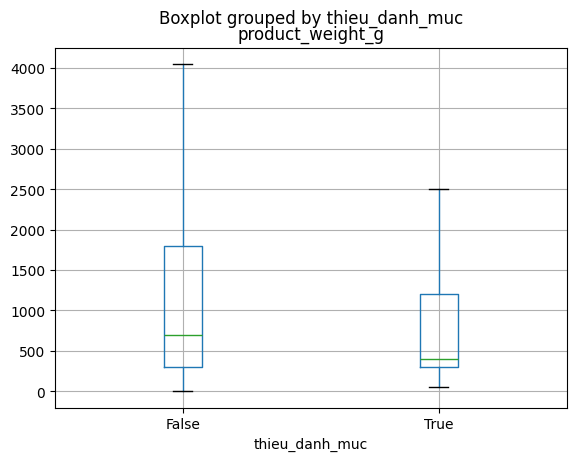

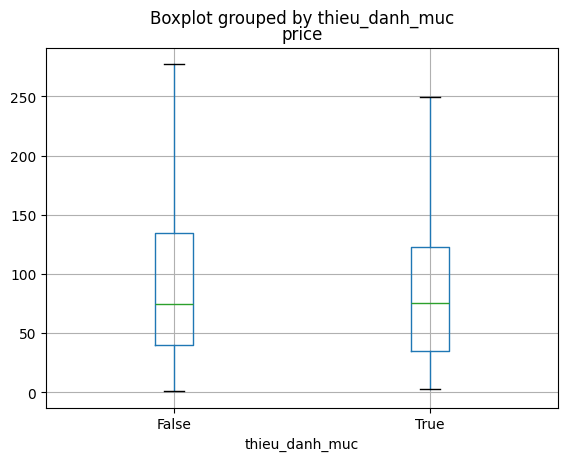

product_category_name      False    True 
product_weight_g count  110498.0   1579.0
                 mean     2098.4   1656.8
                 std      3749.9   3501.0
                 min         0.0     50.0
                 25%       300.0    300.0
                 50%       700.0    400.0
                 75%      1800.0   1200.0
                 max     40425.0  30000.0
price            count  110498.0   1579.0
                 mean      120.8    113.0
                 std       183.5    199.1
                 min         0.8      3.0
                 25%        39.9     35.0
                 50%        75.0     75.0
                 75%       135.0    123.0
                 max      6735.0   3980.0


In [21]:
mask = df['product_category_name'].isna()
print('so dong thieu danh muc:', mask.sum())
print('ty le tren df         :', round(mask.mean() * 100, 2), '%')
print()

d = df.assign(thieu_danh_muc=mask)
d.boxplot(column='product_weight_g', by='thieu_danh_muc', showfliers=False)
plt.show()
d.boxplot(column='price', by='thieu_danh_muc', showfliers=False)
plt.show()

print(df.groupby(mask)[['product_weight_g', 'price']].describe().T.round(1))

> **Kết luận:** 1,579 dòng (1.41%) thiếu danh mục; nhóm này nhẹ hơn rõ rệt (trung vị 400 g so với 700 g) nhưng cùng trung vị giá 75, nên việc thiếu danh mục không ngẫu nhiên theo cân nặng.

**Bước 2:** kiểm tra nhãn unknown chưa trùng tên danh mục có sẵn, gán nhãn cho hai cột danh mục của các dòng thiếu và ghi vào nhật ký thay đổi.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Gán unknown giữ lại thông tin "thiếu danh mục" như một nhóm riêng, thay vì xóa dòng hay điền một danh mục đoán.
- Việc thiếu không ngẫu nhiên theo cân nặng (Bước 1), nên loại nhóm này là bỏ một nhóm sản phẩm có đặc điểm riêng.
- Giữ dòng không làm mất cân nặng, kích thước và tọa độ đã đầy đủ sau 3.4.2 và 3.4.3.

**Hạn chế:** nhóm unknown gộp nhiều loại sản phẩm khác nhau nên không mang ý nghĩa của một danh mục.

In [22]:
so_dong_thieu = df['product_category_name'].isna().sum()

print('unknown da la ten danh muc co san:', (df[['product_category_name', 'product_category_name_english']] == 'unknown').any().any())

df['product_category_name'] = df['product_category_name'].fillna('unknown')
df['product_category_name_english'] = df['product_category_name_english'].fillna('unknown')

print(df[['product_category_name', 'product_category_name_english']].isna().sum())
ghi_thay_doi('3.4.4', 'gan nhan unknown cho danh muc thieu', int(so_dong_thieu), 'Quyết định', 'Không')

unknown da la ten danh muc co san: False
product_category_name            0
product_category_name_english    0
dtype: int64
3.4.4    gan nhan unknown cho danh muc thieu        anh huong 1579 dong


> **Kết luận:** gán nhãn unknown cho 1,579 dòng; nhãn chưa trùng tên danh mục có sẵn và hai cột danh mục không còn giá trị thiếu.

#### 3.4.5 Kiểm tra lại giá trị thiếu

Đếm tổng ô thiếu của df sau 3.4.2, 3.4.3 và 3.4.4.

In [23]:
print('tong o thieu:', df.isnull().sum().sum())

tong o thieu: 0


> **Kết luận:** df không còn ô thiếu nào.

### 3.5 Xác định phạm vi dữ liệu

**Mục đích:** giới hạn dữ liệu ở đơn đã giao và khoảng thời gian phân tích; đây là chọn dữ liệu theo phạm vi bài toán chứ không sửa lỗi, nên cả hai quy tắc thuộc loại Quyết định.

#### 3.5.1 Chỉ giữ đơn đã giao

**Bước 1:** đếm số dòng theo order_status, rồi đếm số dòng, số dòng chưa giao và tỷ lệ chưa giao theo tháng mua.

In [24]:
print(df['order_status'].value_counts())
print()

thang_mua = pd.to_datetime(df['order_purchase_timestamp']).dt.to_period('M')
chua_giao = df['order_status'] != 'delivered'
bang = pd.DataFrame({'so_dong': thang_mua.value_counts().sort_index(), 'don_chua_giao': chua_giao.groupby(thang_mua).sum()})
bang['ty_le_chua_giao'] = (bang['don_chua_giao'] / bang['so_dong'] * 100).round(2)
print(bang)

order_status
delivered      109642
shipped          1178
canceled          536
processing        356
invoiced          355
unavailable         7
approved            3
Name: count, dtype: int64

                          so_dong  don_chua_giao  ty_le_chua_giao
order_purchase_timestamp                                         
2016-09                         6              3            50.00
2016-10                       363             50            13.77
2016-12                         1              0             0.00
2017-01                       954             42             4.40
2017-02                      1950             92             4.72
2017-03                      2985            102             3.42
2017-04                      2663            115             4.32
2017-05                      4115            132             3.21
2017-06                      3552             93             2.62
2017-07                      4494            101             2.25
2017-08       

> **Kết luận:**
>
> - Đa số dòng (109,642) thuộc đơn delivered.
> - 2016-09, 2016-12 và 2018-09 chỉ có 6, 1 và 1 dòng; các tháng còn lại có từ 363 dòng trở lên.

**Bước 2:** chỉ giữ các dòng có order_status = delivered.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Phạm vi bài toán là phí của giao dịch đã hoàn tất, gắn với một lần vận chuyển đã thực sự diễn ra.
- Đơn bị hủy hoặc không khả dụng có thể không phát sinh vận chuyển; đơn ở trạng thái trung gian (shipped, invoiced, processing, approved) chưa hoàn tất giao dịch.

In [25]:
df = step(df, df['order_status'] == 'delivered', '3.5.1', 'chi giu order_status = delivered', 'Quyết định', 'Không')

3.5.1    chi giu order_status = delivered            112077 ->  109642 (loai 2435)


> **Kết luận:** loại 2,435 dòng; df còn 109,642 dòng, đều thuộc đơn delivered.

#### 3.5.2 Giới hạn khoảng thời gian

**Bước 1:** chuyển order_purchase_timestamp sang kiểu ngày giờ và vẽ số dòng theo tháng mua.

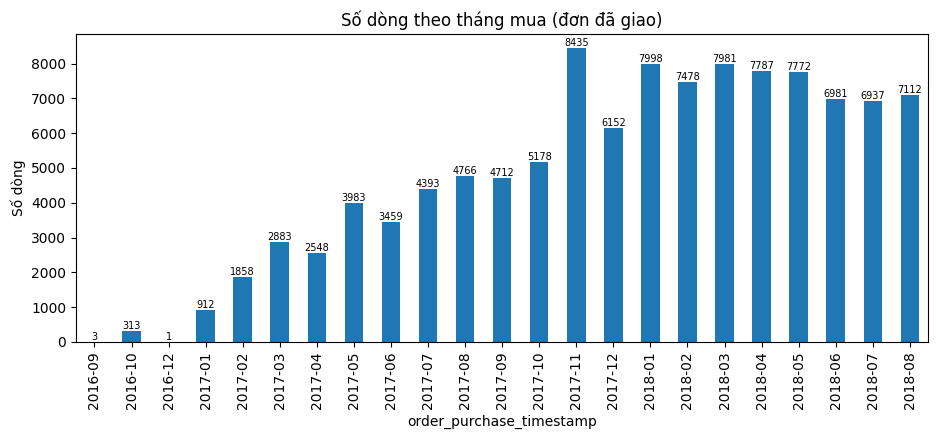

In [26]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
so_dong_thang = df['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

ax = so_dong_thang.plot(kind='bar', figsize=(11, 4))
ax.bar_label(ax.containers[0], fontsize=7)
plt.ylabel('Số dòng')
plt.title('Số dòng theo tháng mua (đơn đã giao)')
plt.show()

> **Kết luận:** năm 2016 chỉ có 3 tháng rời rạc (2016-09, 2016-10, 2016-12) với rất ít dòng và không có 2016-11, còn từ 2017-01 mỗi tháng đều có dữ liệu liên tục đến 2018-08.

**Bước 2:** giữ các đơn mua từ 01/01/2017 đến hết 31/08/2018 và in thời điểm sớm nhất, muộn nhất sau khi lọc.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Dữ liệu 2016 thưa và không liên tục, không đủ để chia tập theo thời gian; từ 01/2017 mỗi tháng đều có dữ liệu liên tục (Bước 1).
- Cận trên 08/2018 là tháng cuối có đơn đã giao: 2018-09 có 100% dòng chưa giao (3.5.1).
- Tỷ lệ dòng chưa giao của 2018-08 tương đương các tháng trước (3.5.1), nên tháng cuối không thiếu đơn do chưa kịp giao.

**Hạn chế:** mô hình không được kiểm chứng trên dữ liệu năm 2016.

In [27]:
keep_time = (df['order_purchase_timestamp'] >= '2017-01-01') & (df['order_purchase_timestamp'] < '2018-09-01')
df = step(df, keep_time, '3.5.2', 'thoi gian 01/2017 den 08/2018', 'Quyết định', 'Không')
print('som nhat  :', df['order_purchase_timestamp'].min())
print('muon nhat :', df['order_purchase_timestamp'].max())

3.5.2    thoi gian 01/2017 den 08/2018               109642 ->  109325 (loai 317)
som nhat  : 2017-01-05 11:56:06
muon nhat : 2018-08-29 15:00:37


> **Kết luận:** loại 317 dòng; df còn 109,325 dòng, thời gian từ 2017-01-05 đến 2018-08-29.

### 3.6 Xử lý giá trị sai miền

**Nguyên nhân:** 3.1.5 đếm cân nặng bằng 0 theo sản phẩm của products; sau khi ghép và lọc, cần đếm lại theo dòng của df.

**Loại quy tắc:** Bắt buộc, không xem freight_value.

Đếm dòng vi phạm từng điều kiện hợp lệ (price > 0, freight_value không âm, cân nặng và 3 kích thước > 0), rồi lọc một lần bằng step().

In [28]:
cot = ['price', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
print((df[cot] <= 0).sum())
print('freight < 0 :', (df['freight_value'] < 0).sum())
print('san pham nang 0 g:', df.loc[df['product_weight_g'] <= 0, 'product_id'].nunique())

valid_value = (df[cot] > 0).all(axis=1) & (df['freight_value'] >= 0)
df = step(df, valid_value, '3.6', 'loai gia tri sai mien', 'Bắt buộc', 'Không')

price                0
product_weight_g     8
product_length_cm    0
product_height_cm    0
product_width_cm     0
dtype: int64
freight < 0 : 0
san pham nang 0 g: 4
3.6      loai gia tri sai mien                       109325 ->  109317 (loai 8)


> **Kết luận:** chỉ product_weight_g có giá trị sai miền (8 dòng thuộc 4 sản phẩm nặng 0 gam); sau khi loại, df còn 109,317 dòng.

### 3.7 Kiểm tra biến mục tiêu freight_value

**Mục đích:** kiểm tra riêng chất lượng của freight_value, vì các mục 3.1 đến 3.6 chủ yếu kiểm tra đặc trưng.

#### 3.7.1 Phân phối

Vẽ histogram của freight_value từ 0 đến 100 kèm vạch trung vị, in thống kê mô tả và số dòng freight_value = 0.

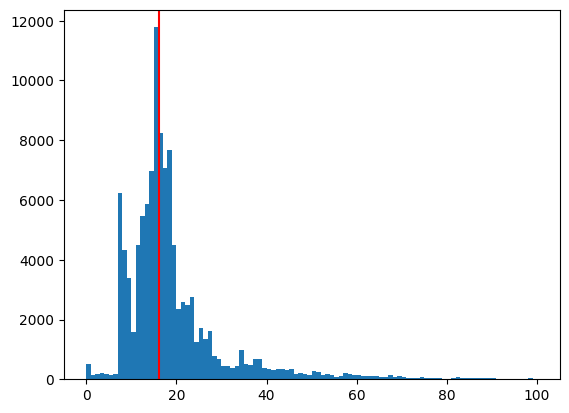

count    109317.00
mean         19.94
std          15.72
min           0.00
25%          13.07
50%          16.25
75%          21.15
max         409.68
Name: freight_value, dtype: float64
freight = 0: 380


In [29]:
f = df['freight_value']

plt.hist(f, bins=100, range=(0, 100))
plt.axvline(f.median(), color='red')
plt.show()

print(f.describe().round(2))
print('freight = 0:', (f == 0).sum())

> **Kết luận:**
>
> - freight_value tập trung quanh trung vị 16.25; phân phối lệch phải với đuôi dài, giá trị lớn nhất là 409.68.
> - 380 dòng có freight_value = 0.

#### 3.7.2 Kiểm tra freight_value = 0

**Câu hỏi:** vì sao có 380 dòng freight_value = 0?

**Giả thuyết:** phí bằng 0 vì người bán và khách ở gần nhau.

So khoảng cách trung bình và trung vị giữa người bán và khách của nhóm freight_value = 0 với nhóm còn lại.

In [30]:
kc = haversine_km(df['s_lat'], df['s_lng'], df['c_lat'], df['c_lng'])
zero = df['freight_value'] == 0

print(kc.groupby(zero).agg(['mean', 'median']).round(1))

                mean  median
freight_value               
False          595.5   431.3
True           675.2   505.6


> **Kết luận:** giả thuyết bị bác bỏ vì nhóm freight_value = 0 không ở gần hơn nhóm còn lại.
>
> | Nhóm | Khoảng cách trung bình | Khoảng cách trung vị |
> |---|---|---|
> | freight_value = 0 | 675.2 km | 505.6 km |
> | freight_value > 0 | 595.5 km | 431.3 km |

#### 3.7.3 Quyết định với freight_value = 0

**Quyết định:** loại 380 dòng freight_value = 0.

**Loại quy tắc:** Quyết định, có xem freight_value.

**Lý do:**

- Giá trị 0 không được giải thích bằng khoảng cách (3.7.2).
- Dữ liệu không có cột nào cho biết lý do phí bằng 0, nên giữ các dòng này buộc mô hình học một mức phí mà các đặc trưng hiện có không giải thích được.

**Hạn chế:** chưa xác định nguyên nhân (miễn phí vận chuyển, mã giảm giá hay lỗi ghi nhận); mô hình không dự đoán được trường hợp miễn phí vận chuyển.

Loại các dòng freight_value = 0 bằng step() và so trung bình, trung vị của freight_value trước và sau khi loại.

In [31]:
truoc = df['freight_value'].agg(['mean', 'median']).round(2)
df = step(df, df['freight_value'] > 0, '3.7.3', 'loai freight_value = 0', 'Quyết định', 'Có')
sau = df['freight_value'].agg(['mean', 'median']).round(2)

print(pd.DataFrame({'truoc': truoc, 'sau': sau}))

3.7.3    loai freight_value = 0                      109317 ->  108937 (loai 380)
        truoc    sau
mean    19.94  20.01
median  16.25  16.28


> **Kết luận:** loại 380 dòng, df còn 108,937 dòng; trung bình và trung vị gần như không đổi (19.94 thành 20.01 và 16.25 thành 16.28).

### 3.8 Audit trail

**Mục đích:** tổng hợp các bước loại dòng và sửa giá trị, kiểm tra tổng số dòng loại khớp với số dòng cuối.

Tạo hai bảng nhật ký từ audit_rows và change_rows, kiểm tra tổng số dòng loại và cộng theo loại quy tắc.

In [32]:
audit = pd.DataFrame(audit_rows)
thay_doi = pd.DataFrame(change_rows)

print(audit)
print()
print(thay_doi)
print()
print('tong so dong loai:', audit['so_dong_loai'].sum())
print('khop so dong cuoi:', audit['truoc'].iloc[0] - audit['so_dong_loai'].sum() == len(df))
print('ty le dong loai  :', round(audit['so_dong_loai'].sum() / audit['truoc'].iloc[0] * 100, 2), '%')
print()
print(audit.groupby('loai_quy_tac')['so_dong_loai'].sum())

     muc                            quy_tac loai_quy_tac co_xem_freight   truoc     sau  so_dong_loai
0  3.4.2                  loai thieu toa do   Quyết định          Không  112650  112095           555
1  3.4.3  loai thieu can nang va kich thuoc   Quyết định          Không  112095  112077            18
2  3.5.1   chi giu order_status = delivered   Quyết định          Không  112077  109642          2435
3  3.5.2      thoi gian 01/2017 den 08/2018   Quyết định          Không  109642  109325           317
4    3.6              loai gia tri sai mien     Bắt buộc          Không  109325  109317             8
5  3.7.3             loai freight_value = 0   Quyết định             Có  109317  108937           380

     muc                              quy_tac loai_quy_tac co_xem_freight  so_dong_anh_huong
0  3.4.4  gan nhan unknown cho danh muc thieu   Quyết định          Không               1579

tong so dong loai: 3713
khop so dong cuoi: True
ty le dong loai  : 3.3 %

loai_quy_tac
Bắt buộc   

> **Kết luận:** 6 bước loại tổng cộng 3,713 dòng (3.30%), từ 112,650 xuống 108,937; tổng khớp số dòng cuối.
>
> | Mục | Quy tắc | Loại quy tắc | Có xem freight_value | Số dòng loại |
> |---|---|---|---|---|
> | 3.4.2 | Thiếu tọa độ | Quyết định | Không | 555 |
> | 3.4.3 | Thiếu cân nặng và kích thước | Quyết định | Không | 18 |
> | 3.5.1 | Chỉ giữ đơn delivered | Quyết định | Không | 2,435 |
> | 3.5.2 | Thời gian 01/2017 đến 08/2018 | Quyết định | Không | 317 |
> | 3.6 | Giá trị sai miền | Bắt buộc | Không | 8 |
> | 3.7.3 | freight_value = 0 | Quyết định | Có | 380 |
>
> | Bước sửa giá trị | Loại quy tắc | Số dòng ảnh hưởng |
> |---|---|---|
> | 3.4.4 Gắn nhãn unknown cho danh mục thiếu | Quyết định | 1,579 |

---

## 4. Chuyển đổi dữ liệu

**Mục đích:** tạo biến thời gian, kiểm tra ý nghĩa của freight_value ở đơn nhiều sản phẩm, tạo đặc trưng và chốt schema để phục vụ phân tích và mô hình hóa.

### 4.1 Biến thời gian

**Mục đích:** tạo t_days (số ngày kể từ 01/01/2017) và month (nhãn tháng dạng YYYY-MM) từ order_purchase_timestamp.

**Lưu ý:** mốc 01/01/2017 là hằng số, không tính từ dữ liệu nên t_days không gây rò rỉ.

Tạo t_days và month, in giá trị nhỏ nhất, lớn nhất.

In [33]:
T0 = pd.to_datetime('2017-01-01')
df['t_days'] = (df['order_purchase_timestamp'] - T0).dt.days
df['month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)

print('t_days:', df['t_days'].min(), '->', df['t_days'].max())
print('month :', df['month'].min(), '->', df['month'].max(), ',', df['month'].nunique(), 'gia tri')

t_days: 4 -> 605
month : 2017-01 -> 2018-08 , 20 gia tri


> **Kết luận:** t_days nhận giá trị từ 4 đến 605; month nhận 20 giá trị liên tiếp từ 2017-01 đến 2018-08.

### 4.2 Bổ sung số sản phẩm của đơn

**Mục đích:** thêm order_n_items, số sản phẩm của mỗi đơn, đếm trên items gốc vì đây là thông tin có tại thời điểm đặt hàng, không phụ thuộc vào các dòng bị loại ở phần 3.

Gán số sản phẩm của đơn từ items gốc vào df và in kích thước df.

In [34]:
df['order_n_items'] = df['order_id'].map(items.groupby('order_id').size())
print(df.shape)

(108937, 27)


> **Kết luận:** df thêm cột order_n_items, số dòng giữ nguyên 108,937.

### 4.3 Ý nghĩa của freight_value ở đơn nhiều sản phẩm

**Câu hỏi:** ở đơn nhiều sản phẩm, freight của cả đơn có bị chia cho các sản phẩm không (nguồn không nêu cách chia, 2.4)?

**Cách làm:** lấy freight trung vị của cùng sản phẩm, cùng người bán, cùng bang khách ở đơn một sản phẩm làm mức đối chiếu, rồi so với freight của các dòng thuộc đơn nhiều sản phẩm. Nếu phí bị chia thì hộp của đơn nhiều sản phẩm phải thấp hơn rõ rệt so với mức đối chiếu.

**Loại quy tắc:** Quyết định, có xem freight_value; không loại hay sửa dòng nào nên không có trong audit trail.

**Lưu ý:** mục này đặt ở phần 4 vì kết quả quyết định việc giữ grain cấp sản phẩm trước khi chốt grain ở 4.4.

Ghép mức đối chiếu (phi_mot_mon) cho các dòng thuộc đơn nhiều sản phẩm và vẽ boxplot cùng freight_value thực tế của các dòng đó.

dong thuoc don nhieu san pham: 23081
dong co muc doi chieu        : 10077


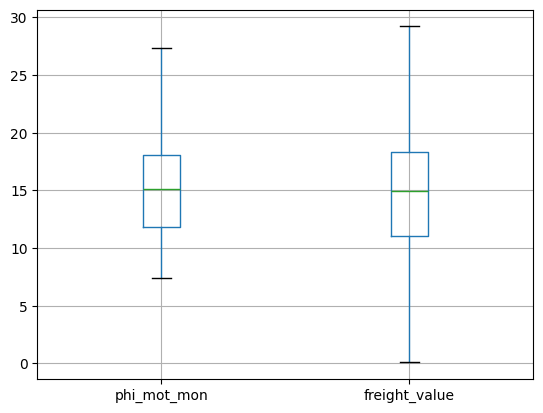

In [35]:
khoa = ['product_id', 'seller_id', 'customer_state']
phi_mot_mon = df[df['order_n_items'] == 1].groupby(khoa)['freight_value'].median().rename('phi_mot_mon')
nhieu_mon = df[df['order_n_items'] > 1].join(phi_mot_mon, on=khoa).dropna(subset=['phi_mot_mon'])

print('dong thuoc don nhieu san pham:', len(df[df['order_n_items'] > 1]))
print('dong co muc doi chieu        :', len(nhieu_mon))

nhieu_mon[['phi_mot_mon', 'freight_value']].boxplot(showfliers=False)
plt.show()

> **Kết luận:** hai hộp gần như trùng nhau (trung vị khoảng 15 ở cả hai nhóm, khoảng tứ phân vị khoảng 11 đến 18), nên không có dấu hiệu freight của cả đơn bị chia cho các sản phẩm.

**Quyết định:** giữ nguyên freight_value ở grain cấp sản phẩm, không gộp theo đơn và không chia lại phí.

**Lý do:** hai hộp trùng nhau nên freight_value của từng dòng được giữ nguyên; gộp theo đơn sẽ mất cân nặng, kích thước và danh mục riêng của từng sản phẩm.

**Hạn chế:**

- Chỉ 10,077 trong 23,081 dòng thuộc đơn nhiều sản phẩm có mức đối chiếu; các dòng còn lại chưa kiểm chứng.
- Cách tính phí của Olist không được công bố, nên kết luận chỉ dựa trên quan hệ quan sát được.

### 4.4 Chốt grain

**Mục đích:** xác nhận grain của bảng cuối là một sản phẩm trong một đơn, xác định bởi cặp (order_id, order_item_id).

Đếm dòng trùng theo grain.

In [36]:
GRAIN = ['order_id', 'order_item_id']
print('trung theo grain:', df.duplicated(subset=GRAIN).sum())

trung theo grain: 0


> **Kết luận:** không có dòng trùng theo (order_id, order_item_id), nên cặp này xác định duy nhất từng dòng.

### 4.5 Tạo đặc trưng

**Mục đích:** tạo 3 đặc trưng số từ các cột đã làm sạch.

- distance_km: khoảng cách đường chim bay giữa người bán và khách, tính bằng haversine_km().
- volume_cm3: tích của chiều dài, chiều cao và chiều rộng.
- same_state: bằng 1 nếu seller_state trùng customer_state, ngược lại bằng 0.

**Lưu ý:** đường chim bay không phải quãng đường vận chuyển thực; ba cạnh thô được giữ bên cạnh volume_cm3 vì hai sản phẩm cùng thể tích có thể khác hình dạng.

Tạo ba đặc trưng và in thống kê mô tả.

In [37]:
df['distance_km'] = haversine_km(df['s_lat'], df['s_lng'], df['c_lat'], df['c_lng'])
df['volume_cm3'] = df['product_length_cm'] * df['product_height_cm'] * df['product_width_cm']
df['same_state'] = (df['seller_state'] == df['customer_state']).astype(int)

print(df[['distance_km', 'volume_cm3', 'same_state']].describe().round(2))

       distance_km  volume_cm3  same_state
count    108937.00   108937.00   108937.00
mean        595.47    15213.89        0.36
std         587.43    23301.71        0.48
min           0.00      168.00        0.00
25%         182.15     2850.00        0.00
50%         431.31     6468.00        0.00
75%         790.87    18375.00        1.00
max        3398.49   296208.00        1.00


> **Kết luận:** ba đặc trưng đầy đủ cho 108,937 dòng.
>
> | Đặc trưng | Trung bình | Trung vị | Nhỏ nhất | Lớn nhất |
> |---|---|---|---|---|
> | distance_km | 595.47 | 431.31 | 0 | 3,398.49 |
> | volume_cm3 | 15,213.89 | 6,468 | 168 | 296,208 |
> | same_state | 0.36 (36% dòng bằng 1) | 0 | 0 | 1 |

### 4.6 Đổi tên cột và chốt schema cuối

**Mục đích:** đổi 7 cột sang tên ngắn (các cột tọa độ s_lat, s_lng, c_lat, c_lng giữ nguyên) và bỏ 3 cột không dùng.

- order_status: chỉ còn một giá trị delivered sau 3.5.1.
- shipping_limit_date: hạn giao cho vận chuyển, không thuộc nhóm đầu vào ở 1.3.
- product_category_name: trùng thông tin với tên tiếng Anh (category).

Đổi tên cột, bỏ 3 cột không dùng và in schema cuối.

In [38]:
so_cot_truoc = df.shape[1]
df = df.rename(columns={
    'product_weight_g': 'weight_g',
    'product_length_cm': 'length_cm',
    'product_height_cm': 'height_cm',
    'product_width_cm': 'width_cm',
    'product_category_name_english': 'category',
    'seller_zip_code_prefix': 's_zip',
    'customer_zip_code_prefix': 'c_zip',
})
df = df.drop(columns=['order_status', 'shipping_limit_date', 'product_category_name'])

print('so cot:', so_cot_truoc, '->', df.shape[1])
print(list(df.columns))

so cot: 30 -> 27
['order_id', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'customer_id', 'order_purchase_timestamp', 'weight_g', 'length_cm', 'height_cm', 'width_cm', 'category', 'c_zip', 'customer_state', 's_zip', 'seller_state', 'c_lat', 'c_lng', 's_lat', 's_lng', 't_days', 'month', 'order_n_items', 'distance_km', 'volume_cm3', 'same_state']


> **Kết luận:** schema cuối gồm 108,937 dòng và 27 cột, sau khi đổi tên 7 cột và bỏ 3 cột.

---

## 5. Tự đánh giá và kết luận

**Mục đích:** nêu hạn chế của dữ liệu cuối, ghi đầu ra và tổng kết quy trình.

### 5.1 Hạn chế của dữ liệu cuối

**Mục đích:** tổng hợp các hạn chế đã ghi ở các mục trước và đếm thêm hai hạn chế trên bảng cuối.

Đếm dòng có distance_km = 0, dòng cùng mã bưu chính và dòng có danh mục unknown.

In [39]:
print('distance_km = 0   :', (df['distance_km'] == 0).sum())
print('cung ma buu chinh :', (df['s_zip'] == df['c_zip']).sum())
print('category = unknown:', (df['category'] == 'unknown').sum())

distance_km = 0   : 26
cung ma buu chinh : 26
category = unknown: 1510


> **Kết luận:** dữ liệu cuối còn 7 hạn chế cần lưu ý khi dùng cho mô hình.
>
> | Hạn chế | Số liệu | Mục |
> |---|---|---|
> | Loại dòng thiếu tọa độ, chưa biết các dòng bị loại có khác phần còn lại về freight_value hay không | 555 dòng | 3.4.2 |
> | Tọa độ là trung vị theo mã bưu chính, chưa đối chiếu với ranh giới của bang | 9,723 điểm cách tọa độ đại diện trên 10 km | 3.2.2 |
> | distance_km là đường chim bay giữa hai mã bưu chính | 26 dòng distance_km = 0, bằng số dòng cùng mã bưu chính | 4.5 |
> | Danh mục unknown gộp nhiều loại sản phẩm | 1,510 dòng trên bảng cuối (1,579 dòng lúc gán nhãn) | 3.4.4 |
> | Loại freight_value = 0 dựa trên biến mục tiêu, chưa rõ nguyên nhân | 380 dòng | 3.7.3 |
> | Chỉ một phần dòng của đơn nhiều sản phẩm được kiểm chứng cách tính freight | 10,077 trong 23,081 dòng | 4.3 |
> | Không có hãng vận chuyển, giá nhiên liệu, hình thức giao | Không có trong dữ liệu | 2.4 |

### 5.2 Đầu ra

Ghi bảng cuối ra olist_freight_clean.csv, rồi đọc lại để so kích thước, số ô thiếu và số dòng trùng grain với df.

In [40]:
output_dir = 'output/'
os.makedirs(output_dir, exist_ok=True)

df.to_csv(output_dir + 'olist_freight_clean.csv', index=False, encoding='utf-8-sig')

check = pd.read_csv(output_dir + 'olist_freight_clean.csv')
print('df hien tai :', df.shape)
print('file da luu :', check.shape)
print('tong o thieu:', check.isna().sum().sum())
print('trung grain :', check[GRAIN].duplicated().sum())

df hien tai : (108937, 27)
file da luu : (108937, 27)
tong o thieu: 0
trung grain : 0


> **Kết luận:** olist_freight_clean.csv khớp df, gồm 108,937 dòng và 27 cột, không ô thiếu, không trùng grain.

### 5.3 Kết luận

Bảng cuối gồm 108,937 dòng, 27 cột, mỗi dòng là một sản phẩm trong một đơn đã giao từ 01/2017 đến 08/2018, sẵn sàng cho bước khám phá dữ liệu và xây dựng mô hình dự đoán freight_value.

- Phần làm sạch loại 3,713 dòng (3.30%), từ 112,650 xuống 108,937: 8 dòng theo quy tắc Bắt buộc và 3,705 dòng theo quy tắc Quyết định (3.8).
- Hai quyết định có xem freight_value: loại 380 dòng freight_value = 0 sau khi giả thuyết "người bán và khách ở gần nhau" bị bác bỏ (3.7.3), và giữ nguyên freight_value ở grain cấp sản phẩm (4.3).
- Dòng thiếu tọa độ bị loại thay vì điền theo bang vì điền theo bang lệch trung bình 79.6 km (3.4.2).
- Một bước sửa giá trị không loại dòng: gắn nhãn unknown cho 1,579 dòng thiếu danh mục (3.4.4).

**Đối chiếu tiêu chí hoàn thành (1.4):** bảng cuối đạt cả 5 tiêu chí; căn cứ ở 3.8 (số dòng và nhãn quy tắc khớp), 3.6, 4.4 và 5.2 (không sai miền, không trùng grain, không thiếu), 2.1 (dữ liệu cố định, không có bước ngẫu nhiên) và 5.1 (hạn chế).

**Việc chuyển sang bước sau:**

- So kết quả mô hình khi huấn luyện có và không có các dòng freight_value = 0.
- Báo cáo sai số riêng cho đơn nhiều sản phẩm (4.3) và cho nhóm category = unknown.

### 5.4 Nguồn tham khảo

- Olist, Brazilian E-Commerce Public Dataset by Olist, Kaggle: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (mô tả dữ liệu và định nghĩa cột).
- Creative Commons, Attribution-NonCommercial-ShareAlike 4.0 International: https://creativecommons.org/licenses/by-nc-sa/4.0/ (điều kiện của giấy phép dữ liệu).
- EMARKETER, Extra costs are the top reason consumers abandon online carts: https://www.emarketer.com/content/extra-costs-are-the-top-reason-consumers-abandon-online-carts (số liệu khảo sát của Baymard Institute ở 1.1).
- Mundo Logística, Valor do frete é fator de decisão de compra para brasileiros: https://mundologistica.com.br/noticias/valor-frete-fator-decisao-compra-brasileiros (số liệu NuvemCommerce 2026 ở 1.1).
- How to Document Your Data Cleaning Steps, r-statistics.co: https://r-statistics.co/How-to-Document-Your-Data-Cleaning-Steps.html (ghi lý do và số dòng của từng quy tắc làm sạch).
- Phase 3 of the CRISP-DM Process Model: Data Preparation, Dummies.com: https://www.dummies.com/article/phase-3-of-the-crisp-dm-process-model-data-preparation-148177 (tách chọn dữ liệu và làm sạch dữ liệu).
- IBGE, Pontos extremos do Brasil: https://educa.ibge.gov.br/criancas/voce-sabia/23101-pontos-extremos.html (tên các điểm cực Bắc, Nam, Đông, Tây).
- List of extreme points of Brazil, Wikipedia: https://en.wikipedia.org/wiki/List_of_extreme_points_of_Brazil (tọa độ các điểm cực, gồm quần đảo Martim Vaz ở kinh độ khoảng 28°51′ Tây).
- zimmel-virk, olist-freight-cost-regression (GitHub): https://github.com/zimmel-virk/olist-freight-cost-regression (dự án tham khảo về dự đoán phí vận chuyển Olist).